# KHAI PHÁ DỮ LIỆU TUYỂN SINH ĐẠI HỌC VIỆT NAM (2010 – 2025)

Dự án áp dụng các kỹ thuật Khai phá dữ liệu (Data Mining) và Học máy (Machine Learning) để dự báo điểm chuẩn trúng tuyển đại học, phân loại mức độ cạnh tranh ngành đào tạo và dự báo khả năng trúng tuyển của các chương trình đào tạo trên toàn quốc.

Notebook này được thiết kế bám sát cấu trúc của **CHƯƠNG 5** trong báo cáo đồ án, phân tích trên dữ liệu lịch sử tuyển sinh phương thức Điểm thi THPT.

## 5.1 Đặt vấn đề và mục tiêu khai phá dữ liệu

### 5.1.1 Bối cảnh thực tiễn và bài toán nghiên cứu
- Dự báo điểm chuẩn tuyển sinh đại học là bài toán mang ý nghĩa thực tiễn to lớn đối với học sinh, phụ huynh và các cơ sở giáo dục đại học.
- Đồ án giải quyết 3 bài toán khai phá dữ liệu cốt lõi:
  1. **Bài toán Hồi quy (Regression):** Dự báo mức điểm chuẩn trúng tuyển thực tế (`target_score`) theo thang điểm 30.
  2. **Bài toán Phân loại đa lớp (Multi-class Classification):** Phân loại ngành tuyển sinh vào 4 nhóm điểm cạnh tranh (`Dưới 18`, `Từ 18 đến dưới 22`, `Từ 22 đến dưới 25`, `Từ 25 trở lên`).
  3. **Bài toán Phân loại nhị phân (Binary Classification):** Dự báo ngành có thuộc nhóm điểm chuẩn cao (>= 24.0 điểm) hay không.

### 5.1.2 Nguồn dữ liệu sử dụng
- Nguồn dữ liệu đầu vào được lấy từ thư mục `PythonScripts/cleaned-data`, bao gồm:
  - `cleaned-cutoff-scores.csv`: 103,403 bản ghi điểm chuẩn tuyển sinh từ năm 2010 đến 2025 (sử dụng trực tiếp trường `score_mark`, không sử dụng `converted_score_mark`).
  - `cleaned-majors.csv`: 506 danh mục ngành đào tạo chuẩn hóa phục vụ ánh xạ nhóm ngành (`major_groups`).
  - `cleaned-score-blocks.csv`: 451 mã tổ hợp môn xét tuyển chuẩn quốc gia.

In [1]:
import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn thư mục gốc dự án
NOTEBOOK_DIR = Path(os.getcwd())
PROJECT_DIR = Path('D:/UNIDOCS/IS217.R11-OLAP')

# Cấu hình hiển thị đồ họa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', None)

print('Môi trường và các thư viện phân tích đã sẵn sàng!')

Môi trường và các thư viện phân tích đã sẵn sàng!


## 5.2 Kiểm tra và tiền xử lý dữ liệu

### 5.2.1 Tổng quan dữ liệu sạch đầu vào (Data Overview)
Dữ liệu nguồn tại `PythonScripts/cleaned-data/cleaned-cutoff-scores.csv` là dữ liệu đã được làm sạch hoàn chỉnh qua các bước: xử lý giá trị rỗng, loại bỏ bản ghi không hợp lệ, khử trùng lặp hoàn toàn, quy đổi thang điểm 40 về thang điểm 30, và loại trừ ngoại lai IQR theo từng phương thức.

Trong notebook khai phá này, chúng ta **không cần làm sạch lại dữ liệu thô (không chuẩn hóa văn bản, không lọc ngoại lai thang điểm)** mà tập trung vào **Chọn lọc và định hình tập dữ liệu khai phá (Data Selection for Mining)** cho phương thức Điểm thi THPT.

In [2]:
SCORES_PATH = PROJECT_DIR / 'PythonScripts/cleaned-data/cleaned-cutoff-scores.csv'
MAJORS_PATH = PROJECT_DIR / 'PythonScripts/cleaned-data/cleaned-majors.csv'

scores_df = pd.read_csv(SCORES_PATH, dtype={'school_id': str, 'score_code': str})
majors_df = pd.read_csv(MAJORS_PATH)

print(f"Tổng số bản ghi trong cleaned-cutoff-scores.csv : {len(scores_df):,}")
print(f"Tổng số danh mục ngành trong cleaned-majors.csv : {len(majors_df):,}")
display(scores_df.head(3))

Tổng số bản ghi trong cleaned-cutoff-scores.csv : 103,403


Tổng số danh mục ngành trong cleaned-majors.csv : 506


,school_id,school_name,school_type,school_short_name,province_id,province_name,score_code,score_name,score_blocks,score_mark,score_year,score_introtext,score_admission_name
0,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử,A00;A01,16.00,2018,NaN,Điểm thi THPT
1,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Điểm chuẩn trúng tuyển (Toán nhân 2),Điểm học bạ
2,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Quy đổi thang điểm 30,Điểm học bạ


### 5.2.2 Chọn lọc và định hình tập dữ liệu khai phá (Data Selection for Mining)

Quy trình chọn lọc tập dữ liệu khai phá được thực hiện nghiêm ngặt qua 4 bước, ở mỗi bước đều in rõ số lượng bản ghi trước và sau khi áp dụng:

#### Bước 1: Lọc phương thức xét tuyển mục tiêu "Điểm thi THPT"
- Trích xuất tập con có phương thức `score_admission_name == 'Điểm thi THPT'`. Đây là phương thức có lịch sử xét tuyển liên tục 16 năm và sử dụng thang điểm chuẩn 30 điểm đồng nhất.
- Giữ nguyên toàn bộ 58,064 bản ghi sạch từ nguồn dữ liệu đầu vào.

In [3]:
# Bước 1: Lọc phương thức xét tuyển Điểm thi THPT
n_before_b1 = len(scores_df)

# Lọc phương thức THPT
df_thpt = scores_df[scores_df['score_admission_name'] == 'Điểm thi THPT'].copy()
n_after_b1 = len(df_thpt)

print("Bước 1: Lọc phương thức xét tuyển Điểm thi THPT:")
print(f"   - Số lượng bản ghi trước khi áp dụng       : {n_before_b1:,}")
print(f"   - Số lượng bản ghi sau khi áp dụng Bước 1  : {n_after_b1:,} (Chiếm {n_after_b1/n_before_b1*100:.2f}%)")

Bước 1: Lọc phương thức xét tuyển Điểm thi THPT:
   - Số lượng bản ghi trước khi áp dụng       : 103,403
   - Số lượng bản ghi sau khi áp dụng Bước 1  : 58,064 (Chiếm 56.15%)


#### Bước 2: Xử lý xung đột bản ghi cùng khóa hạt (Grain Conflict Resolution)
- **Định nghĩa khóa hạt tuyển sinh (Grain Key):** `[school_id, score_code, program_name, block_set, score_year, score_admission_name]`.
- Danh sách tổ hợp môn `score_blocks` được sắp xếp theo thứ tự bảng chữ cái để tạo cột chuẩn hóa `block_set`.
- **Grain Conflict:** Với cùng một trường, ngành, tổ hợp môn, năm tuyển sinh và phương thức THPT, nếu tồn tại nhiều mức điểm chuẩn khác nhau (do tuyển bổ sung nhiều đợt hoặc cơ sở phụ), việc giữ lại sẽ tạo ra **nhiễu nhãn mâu thuẫn (Contradictory Label Noise)** cho học máy. Vì vậy, ta phát hiện và loại trừ triệt để các bản ghi bị xung đột, đồng thời giữ lại 1 bản ghi duy nhất nếu trùng khóa và cùng điểm.

In [4]:
# Bước 2: Xử lý xung đột khóa hạt (Grain Conflict Resolution)
n_before_b2 = len(df_thpt)

# Sắp xếp mã tổ hợp môn theo thứ tự chữ cái để đồng nhất khóa hạt
def sort_blocks(val):
    if pd.isna(val): return 'Chưa xác định'
    parts = sorted([p.strip().upper() for p in str(val).split(';') if p.strip()])
    return ';'.join(parts) if parts else 'Chưa xác định'

df_thpt['block_set'] = df_thpt['score_blocks'].map(sort_blocks)
df_thpt['program_name'] = df_thpt['score_name'].fillna('Chưa xác định').astype(str).str.strip()
df_thpt['target_score'] = pd.to_numeric(df_thpt['score_mark'], errors='coerce')
df_thpt['score_year'] = pd.to_numeric(df_thpt['score_year'], errors='coerce').astype(int)

grain_cols = ['school_id', 'score_code', 'program_name', 'block_set', 'score_year', 'score_admission_name']

# Phát hiện các Grain có nhiều mức điểm chuẩn khác nhau
conflicts = df_thpt.groupby(grain_cols, dropna=False)['target_score'].transform('nunique') > 1
df_conflict_records = df_thpt[conflicts]

# Loại bỏ các grain bị xung đột điểm
df_clean_grain = df_thpt[~conflicts].copy()

# Khử các bản ghi trùng khóa và cùng điểm
df_clean_grain = df_clean_grain.drop_duplicates(subset=grain_cols).copy()
n_after_b2 = len(df_clean_grain)

print("Bước 2: Xử lý xung đột khóa hạt (Grain Conflict Resolution):")
print(f"   - Số lượng bản ghi trước khi áp dụng            : {n_before_b2:,}")
print(f"   - Số bản ghi bị loại do xung đột/trùng khóa hạt : {n_before_b2 - n_after_b2:,}")
print(f"   - Số lượng bản ghi sau khi áp dụng Bước 2       : {n_after_b2:,}")

Bước 2: Xử lý xung đột khóa hạt (Grain Conflict Resolution):
   - Số lượng bản ghi trước khi áp dụng            : 58,064
   - Số bản ghi bị loại do xung đột/trùng khóa hạt : 7,221
   - Số lượng bản ghi sau khi áp dụng Bước 2       : 50,843


#### Bước 3: Ánh xạ danh mục nhóm ngành đào tạo (`major_groups`)
- Đối chiếu mã ngành `score_code` và tên chương trình `program_name` với danh mục chuẩn 506 ngành từ `cleaned-majors.csv`.
- Gán thuộc tính `major_groups` phục vụ bài toán học máy.

In [5]:
# Bước 3: Ánh xạ nhóm ngành đào tạo (Major Mapping)
n_before_b3 = len(df_clean_grain)

from collections import defaultdict
major_candidates = defaultdict(set)
for _, r in majors_df.iterrows():
    group = str(r['major_group_name']).strip()
    name = str(r['major_name']).strip().lower()
    codes = [c.strip() for c in str(r.get('score_codes', '')).split(';') if c.strip() and c.strip() != 'nan']
    for code in codes:
        major_candidates[code].add((name, group))

def resolve_major(code, prog_name):
    opts = major_candidates.get(str(code).strip(), set())
    if not opts: return 'Nhóm ngành khác'
    prog_lower = str(prog_name).strip().lower()
    exact = {grp for name, grp in opts if name == prog_lower}
    if exact: return ' | '.join(sorted(exact))
    grps = {g for _, g in opts}
    if len(grps) == 1: return next(iter(grps))
    return 'Nhóm ngành khác'

df_clean_grain['major_groups'] = [resolve_major(c, n) for c, n in zip(df_clean_grain['score_code'], df_clean_grain['program_name'])]
n_after_b3 = len(df_clean_grain)

print("Bước 3: Ánh xạ danh mục nhóm ngành đào tạo (Major Mapping):")
print(f"   - Số lượng bản ghi trước khi áp dụng       : {n_before_b3:,}")
print(f"   - Số lượng bản ghi sau khi áp dụng Bước 3  : {n_after_b3:,}")
print("")
print("Phân bố các nhóm ngành hàng đầu:")
print(df_clean_grain['major_groups'].value_counts().head(5))

Bước 3: Ánh xạ danh mục nhóm ngành đào tạo (Major Mapping):
   - Số lượng bản ghi trước khi áp dụng       : 50,843
   - Số lượng bản ghi sau khi áp dụng Bước 3  : 50,843

Phân bố các nhóm ngành hàng đầu:
major_groups
Nhóm ngành khác                               5137
Sư phạm - Giáo dục                            5015
Kinh tế - Quản trị kinh doanh - Thương Mại    3813
Văn hóa - Chính trị - Khoa học Xã hội         3449
Ngoại giao - Ngoại ngữ                        3005
Name: count, dtype: int64


#### Bước 4: Định hình đặc trưng và biến mục tiêu mô hình hóa
- Tạo biến mục tiêu:
  - `target_score`: Điểm chuẩn thực tế (bài toán hồi quy).
  - `competition_class`: 4 phân khúc điểm (`Dưới 18`, `Từ 18 đến dưới 22`, `Từ 22 đến dưới 25`, `Từ 25 trở lên`).
  - `is_high_score`: 1 nếu >= 24.0, 0 nếu < 24.0 (bài toán nhị phân).
- Tạo đặc trưng độ trễ thời gian: Nối điểm chuẩn đúng năm trước liền kề (`previous_year_score`) và tạo biến cờ `has_previous_year_score`.

Tập dữ liệu nghiên cứu chuẩn hoàn thiện: 50,843 bản ghi.
Tỷ lệ có dữ liệu điểm năm trước: 36.95%

Thống kê mô tả điểm chuẩn sau chọn lọc (target_score):


,target_score
count,50843.00
mean,19.20
std,4.52
min,3.00
25%,15.00
50%,18.00
75%,23.00
max,34.00



Số lượng bản ghi hợp lệ theo từng năm tuyển sinh:


,Số bản ghi
score_year,
2010,766
2011,820
2012,1118
2013,1353
2014,1510
2015,2385
2016,2337
2017,3192
2018,3414



Bảng phân bố phân khúc điểm trên tập kiểm thử (Test 2025) và xác định ngưỡng Baseline:


,Phân khúc điểm,Số lượng bản ghi (Test 2025),Tỷ lệ phần trăm
0,Dưới 18 (Lớp đa số),2367,31.48%
1,Từ 22 đến dưới 25,1858,24.71%
2,Từ 18 đến dưới 22,1787,23.77%
3,Từ 25 trở lên,1507,20.04%
4,Tổng cộng,7519,100.0%


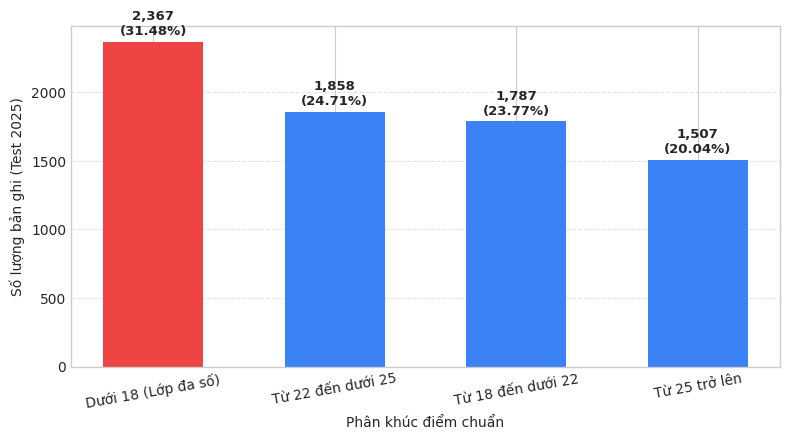

In [6]:
# Bước 4: Tạo nhãn mục tiêu và đặc trưng độ trễ
CLASS_NAMES = ['Dưới 18', 'Từ 18 đến dưới 22', 'Từ 22 đến dưới 25', 'Từ 25 trở lên']
df_final = df_clean_grain.copy()
df_final['competition_class'] = np.searchsorted([18.0, 22.0, 25.0], df_final['target_score'], side='right')
df_final['competition_label'] = df_final['competition_class'].map(dict(enumerate(CLASS_NAMES)))
df_final['is_high_score'] = (df_final['target_score'] >= 24.0).astype(int)

# Nối điểm chuẩn năm liền trước
history = df_final[['school_id', 'score_code', 'program_name', 'block_set', 'score_year', 'target_score']].copy()
history['score_year'] += 1
history = history.rename(columns={'target_score': 'previous_year_score'})

df_final = df_final.merge(history, on=['school_id', 'score_code', 'program_name', 'block_set', 'score_year'], how='left')
df_final['has_previous_year_score'] = df_final['previous_year_score'].notna().astype(int)

print(f"Tập dữ liệu nghiên cứu chuẩn hoàn thiện: {len(df_final):,} bản ghi.")
print(f"Tỷ lệ có dữ liệu điểm năm trước: {df_final['has_previous_year_score'].mean()*100:.2f}%")
print("")
print("Thống kê mô tả điểm chuẩn sau chọn lọc (target_score):")
display(df_final[['target_score']].describe().round(2))
print("")
print("Số lượng bản ghi hợp lệ theo từng năm tuyển sinh:")
display(df_final['score_year'].value_counts().sort_index().to_frame('Số bản ghi'))

# Bảng phân bố phân khúc điểm trên tập kiểm thử Test 2025 (Cơ sở xác định Baseline)
test_2025 = df_final[df_final['score_year'] == 2025]
vc_test = test_2025['competition_label'].value_counts()
pct_test = test_2025['competition_label'].value_counts(normalize=True) * 100

df_baseline = pd.DataFrame({
    'Phân khúc điểm': vc_test.index,
    'Số lượng bản ghi (Test 2025)': vc_test.values,
    'Tỷ lệ phần trăm': [f"{p:.2f}%" for p in pct_test.values]
})
df_baseline['Phân khúc điểm'] = df_baseline['Phân khúc điểm'].apply(
    lambda x: f"{x} (Lớp đa số)" if 'Dưới 18' in x else x
)

total_row = pd.DataFrame({
    'Phân khúc điểm': ['Tổng cộng'],
    'Số lượng bản ghi (Test 2025)': [len(test_2025)],
    'Tỷ lệ phần trăm': ['100.0%']
})
df_baseline_table = pd.concat([df_baseline, total_row], ignore_index=True)

print("")
print("Bảng phân bố phân khúc điểm trên tập kiểm thử (Test 2025) và xác định ngưỡng Baseline:")
display(df_baseline_table)

# Biểu đồ minh họa phân bố tập Test 2025 (ẩn tiêu đề toàn chart, giữ rõ nhãn các trục)
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_colors = ['#ef4444' if 'Dưới 18' in x else '#3b82f6' for x in df_baseline['Phân khúc điểm']]
bars = ax.bar(df_baseline['Phân khúc điểm'], df_baseline['Số lượng bản ghi (Test 2025)'], color=bar_colors, width=0.55)

ax.set_xlabel('Phân khúc điểm chuẩn')
ax.set_ylabel('Số lượng bản ghi (Test 2025)')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for bar, pct in zip(bars, df_baseline['Tỷ lệ phần trăm']):
    h = bar.get_height()
    ax.annotate(f"{h:,}\n({pct})",
                (bar.get_x() + bar.get_width() / 2., h),
                ha='center', va='bottom',
                xytext=(0, 3), textcoords='offset points',
                fontsize=9.5, fontweight='bold')

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Khám phá trực quan hóa dữ liệu (Exploratory Data Analysis - EDA)
Trực quan hóa phân bố điểm chuẩn, phân bố nhãn bài toán và xu hướng số lượng bản ghi qua các năm.

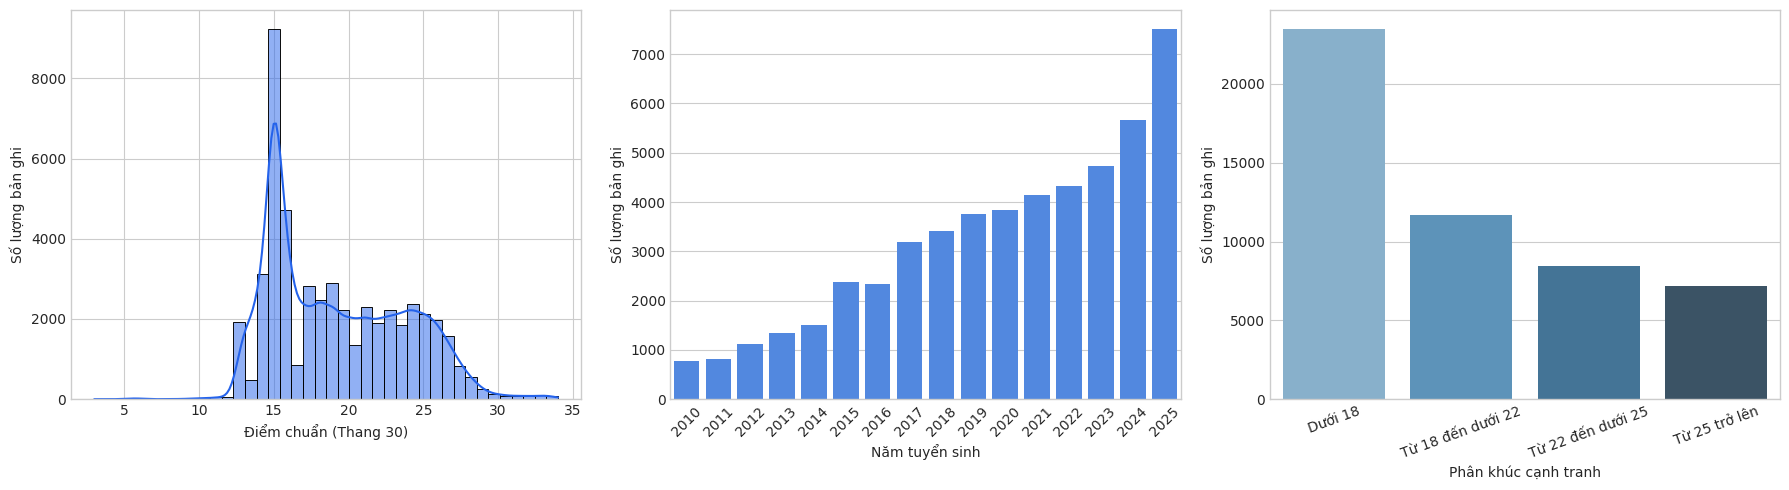

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_final['target_score'], bins=40, kde=True, ax=axes[0], color='#2563eb')
axes[0].set_xlabel('Điểm chuẩn (Thang 30)')
axes[0].set_ylabel('Số lượng bản ghi')

year_counts = df_final['score_year'].value_counts().sort_index()
sns.barplot(x=year_counts.index, y=year_counts.values, ax=axes[1], color='#3b82f6')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_xlabel('Năm tuyển sinh')
axes[1].set_ylabel('Số lượng bản ghi')

class_counts = df_final['competition_label'].value_counts()[CLASS_NAMES]
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[2], palette='Blues_d')
axes[2].tick_params(axis='x', rotation=20)
axes[2].set_xlabel('Phân khúc cạnh tranh')
axes[2].set_ylabel('Số lượng bản ghi')

plt.tight_layout()
plt.show()

## 5.3 Chuẩn bị dữ liệu để bắt đầu huấn luyện mô hình

### 5.3.1 Phân chia tập dữ liệu theo thời gian (Temporal Split)
Để mô phỏng đúng bài toán thực tế và ngăn ngừa rò rỉ dữ liệu (Data Leakage):
- **Tập Train (Huấn luyện ban đầu):** Các năm <= 2023 (37,666 bản ghi - 74.08%)
- **Tập Validation (Kiểm định & Tinh chỉnh):** Năm 2024 (5,658 bản ghi - 11.13%)
- **Tập Test (Kiểm thử độc lập):** Năm 2025 (7,519 bản ghi - 14.79%)

In [8]:
train_df = df_final[df_final['score_year'] <= 2023].copy()
val_df = df_final[df_final['score_year'] == 2024].copy()
test_df = df_final[df_final['score_year'] == 2025].copy()
train_val_df = pd.concat([train_df, val_df], ignore_index=True)

print(f"Tập Train (<= 2023)       : {len(train_df):,} dòng ({len(train_df)/len(df_final)*100:.2f}%)")
print(f"Tập Validation (2024)     : {len(val_df):,} dòng ({len(val_df)/len(df_final)*100:.2f}%)")
print(f"Tập Test (2025)           : {len(test_df):,} dòng ({len(test_df)/len(df_final)*100:.2f}%)")
print(f"Tập Train + Val (<= 2024) : {len(train_val_df):,} dòng")

Tập Train (<= 2023)       : 37,666 dòng (74.08%)
Tập Validation (2024)     : 5,658 dòng (11.13%)
Tập Test (2025)           : 7,519 dòng (14.79%)
Tập Train + Val (<= 2024) : 43,324 dòng


### 5.3.2 Thiết lập Pipeline tiền xử lý và mã hóa đặc trưng
Xây dựng pipeline chuyển đổi không gian đặc trưng đầu vào (𝑋) sang dạng số học bằng `ColumnTransformer` của scikit-learn:
- **Nhánh đặc trưng danh mục (6 biến)**: `school_id`, `school_type`, `province_name`, `program_name`, `major_groups`, `block_set`. Điền giá trị thiếu bằng nhãn `'Chưa xác định'` (`SimpleImputer`). Mã hóa số nguyên thứ tự bằng `OrdinalEncoder` (thiết lập `unknown_value=-1` để tự động xử lý các trường/ngành mới xuất hiện ở tập kiểm thử).
- **Nhánh đặc trưng số học (3 biến)**: `score_year`, `previous_year_score`, `has_previous_year_score`.
Điền giá trị khuyết (các ngành mới mở chưa có lịch sử điểm năm trước) bằng giá trị trung vị (`SimpleImputer`(`strategy='median'`)).

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

CATEGORICAL_FEATURES = ['school_id', 'school_type', 'province_name', 'program_name', 'major_groups', 'block_set']
NUMERIC_FEATURES = ['score_year', 'previous_year_score', 'has_previous_year_score']
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Chưa xác định')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, CATEGORICAL_FEATURES),
    ('num', num_pipeline, NUMERIC_FEATURES)
])

print(f"Danh sách đặc trưng đầu vào ({len(FEATURES)} đặc trưng):")
print(f"  - Danh mục: {CATEGORICAL_FEATURES}")
print(f"  - Số học  : {NUMERIC_FEATURES}")

Danh sách đặc trưng đầu vào (9 đặc trưng):
  - Danh mục: ['school_id', 'school_type', 'province_name', 'program_name', 'major_groups', 'block_set']
  - Số học  : ['score_year', 'previous_year_score', 'has_previous_year_score']


## 5.4 Ứng dụng mô hình thuật toán

### 5.4.1 Đánh giá mô hình
Xây dựng hàm mẫu `run_step` để chuẩn hóa quy trình huấn luyện, dự đoán và đánh giá toàn diện các mô hình học máy với các thông số:
- **`run_step`:** Hàm tính toán và in ra các chỉ số hiệu năng (Accuracy, F1-Score), đồng thời hiển thị chi tiết Classification Report.
- **`Accuracy` (Độ chính xác):** Đo lường tỷ lệ phần trăm các dự đoán đúng trên tổng số mẫu:
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
- **`F1-Score`:** Trung bình điều hòa giữa Precision (độ chuẩn xác) và Recall (độ nhạy), đặc biệt hiệu quả trong đánh giá dữ liệu mất cân bằng:
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$



In [10]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.inspection import permutation_importance

# Khởi tạo từ điển bảng điểm lưu trữ kết quả đánh giá các mô hình theo đúng thứ tự
baseline_results = {}

# Chuẩn bị dữ liệu đặc trưng đã qua xử lý và nhãn mục tiêu
X_train_prep = preprocessor.fit_transform(train_val_df[FEATURES])
X_test_prep = preprocessor.transform(test_df[FEATURES])

y_train_arr = train_val_df['competition_class'].values
y_test_arr = test_df['competition_class'].values

print(f"Kích thước tập huấn luyện (X_train) : {X_train_prep.shape}")
print(f"Kích thước tập kiểm thử   (X_test)  : {X_test_prep.shape}")

def run_step(model, X_train, y_train, X_test, y_test, model_name="Model"):
    """Hàm mẫu huấn luyện, dự đoán và in chỉ số đánh giá Accuracy & F1-Score."""
    print("=" * 60)
    print(f"► ĐANG HUẤN LUYỆN: {model_name}")
    print("=" * 60)
    
    # Huấn luyện
    model.fit(X_train, y_train)
    
    # Dự đoán
    y_pred = model.predict(X_test)
    
    # Tính toán chỉ số
    acc = accuracy_score(y_test, y_pred)
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    
    # Lưu vào từ điển tổng hợp
    baseline_results[model_name] = {
        'Accuracy': acc,
        'F1-Score': f1_weighted,
        'F1-Macro': f1_macro
    }
    
    print(f"  Accuracy: {acc:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  F1-Score (Macro):    {f1_macro:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
    
    return y_pred, acc, f1_weighted


Kích thước tập huấn luyện (X_train) : (43324, 9)
Kích thước tập kiểm thử   (X_test)  : (7519, 9)


### 5.4.2 Decision Tree

#### 5.4.2.1 Cơ sở lý thuyết
Decision Tree (Cây quyết định) là một mô hình học máy đơn giản nhưng mạnh mẽ được sử dụng cho cả bài toán phân loại và hồi quy. Mô hình này hoạt động bằng cách chia nhỏ dữ liệu thành các tập con dựa trên các điều kiện rẽ nhánh trên từng đặc trưng, tạo nên cấu trúc cây phân tầng. Mỗi nút trong cây đại diện cho một điều kiện kiểm tra trên một đặc trưng, và mỗi nhánh là kết quả của điều kiện kiểm tra đó.

**Nguyên lý hoạt động:**
Tại mỗi nút, thuật toán lựa chọn đặc trưng và điểm phân chia (split point) giúp tối ưu hóa độ tinh khiết của dữ liệu, phổ biến nhất là dựa trên chỉ số Gini Impurity hoặc Information Gain (Entropy). Quá trình phân nhánh tiếp tục đệ quy cho đến khi đạt độ sâu tối đa hoặc các nút lá chứa số mẫu nhỏ hơn ngưỡng quy định.

**Ưu điểm:**
- Trực quan, dễ giải thích và minh họa quy trình ra quyết định.
- Không đòi hỏi chuẩn hóa thang đo của dữ liệu đầu vào.
- Khả năng xử lý tốt cả dữ liệu số và dữ liệu phân loại.

**Hạn chế:**
- Rất dễ bị quá khớp (overfitting) nếu không kiểm soát độ sâu hoặc cắt tỉa cây (pruning).
- Nhạy cảm cao với sự biến động nhỏ của dữ liệu huấn luyện, độ ổn định thấp hơn các thuật toán tổ hợp (Ensemble).



#### 5.4.2.2 Xây dựng mô hình
Quy trình xây dựng mô hình Decision Tree gồm 4 bước chuẩn hóa:
- **Bước 1: Thiết lập cấu hình (Khởi tạo):** Khởi tạo `DecisionTreeClassifier` với tham số kiểm soát độ sâu `max_depth=10`, `min_samples_leaf=5`, `random_state=42`.
- **Bước 2: Huấn luyện (Training):** Huấn luyện mô hình trên tập dữ liệu train đã qua mã hóa.
- **Bước 3: Dự đoán (Testing):** Dự đoán trên tập kiểm thử độc lập Test 2025 (`X_test_prep`).
- **Bước 4: Chấm điểm (Evaluation):** Gọi hàm mẫu `run_step` tính toán Accuracy và F1-Score.



In [11]:
from sklearn.tree import DecisionTreeClassifier

# Bước 1: Khởi tạo mô hình Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

# Bước 2, 3, 4: Huấn luyện, Dự đoán và Đánh giá qua run_step
y_pred_dt, acc_dt, f1_dt = run_step(
    dt_model,
    X_train_prep,
    y_train_arr,
    X_test_prep,
    y_test_arr,
    "Decision Tree"
)


► ĐANG HUẤN LUYỆN: Decision Tree


  Accuracy: 0.3986
  F1-Score (Weighted): 0.3795
  F1-Score (Macro):    0.3629

Classification Report:
                   precision    recall  f1-score   support

          Dưới 18     0.5857    0.6079    0.5966      2367
Từ 18 đến dưới 22     0.2729    0.0935    0.1392      1787
Từ 22 đến dưới 25     0.2943    0.3595    0.3236      1858
    Từ 25 trở lên     0.3317    0.4798    0.3922      1507

         accuracy                         0.3986      7519
        macro avg     0.3711    0.3852    0.3629      7519
     weighted avg     0.3884    0.3986    0.3795      7519



#### 5.4.2.3 Kết quả
Kết quả đánh giá mô hình Decision Tree trên tập kiểm thử Test 2025:



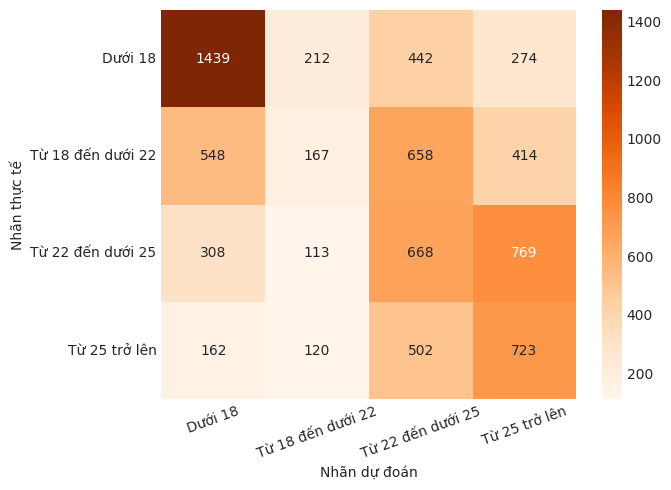

In [12]:
cm_dt = confusion_matrix(y_test_arr, y_pred_dt)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thực tế')
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.4.3 XGBOOST

#### 5.4.3.1 Cơ sở lý thuyết
XGBoost (eXtreme Gradient Boosting) là một thuật toán học máy dựa trên cây quyết định được mở rộng từ Gradient Boosting framework. Nó tối ưu hóa các hàm mất mát thông qua gradient descent và sử dụng các cây quyết định để tạo ra các dự đoán. XGBoost có thể được áp dụng cho cả các bài toán hồi quy (regression) và phân loại (classification).

**Nguyên lý hoạt động:**
XGBoost kết hợp các cây học tập yếu (weak learners) tuần tự thành một cây mô hình mạnh hơn. Quá trình bắt đầu với một cây quyết định đơn giản dự đoán giá trị trung bình của nhãn. Sau đó, trong mỗi vòng lặp, thuật toán xây dựng một cây mới để sửa sai các lỗi của các cây trước đó bằng cách tối ưu hóa gradient của hàm mất mát. Các mẫu dự đoán sai được gán trọng số cao hơn để cây kế tiếp tập trung học. Quá trình lặp lại cho đến khi đạt số cây xác định hoặc không còn cải thiện đáng kể.

**Ưu điểm:**
- Hiệu suất dự đoán vượt trội nhờ thuật toán tối ưu hóa mạnh mẽ.
- Tích hợp kỹ thuật điều chuẩn (L1/L2 regularization) giúp kiểm soát overfitting hiệu quả.
- Tối ưu hóa tính toán song song trên nhiều CPU, tăng tốc độ huấn luyện.

**Hạn chế:**
- Đòi hỏi tài nguyên tính toán cao trên các tập dữ liệu lớn.
- Cần tinh chỉnh nhiều siêu tham số (learning rate, max depth, subsample) để đạt hiệu năng tối đa.



#### 5.4.3.2 Xây dựng mô hình
Quy trình xây dựng mô hình XGBoost gồm 4 bước chuẩn hóa:
- **Bước 1: Thiết lập cấu hình (Khởi tạo):** Khởi tạo `XGBClassifier` với `n_estimators=150`, `learning_rate=0.08`, `max_depth=6`, `random_state=42`.
- **Bước 2: Huấn luyện (Training):** Huấn luyện mô hình trên tập train.
- **Bước 3: Dự đoán (Testing):** Dự báo trên tập kiểm tra độc lập Test 2025 (`X_test_prep`).
- **Bước 4: Chấm điểm (Evaluation):** Tính toán các chỉ số Accuracy và F1-Score qua hàm `run_step`.



In [13]:
from xgboost import XGBClassifier

# Bước 1: Khởi tạo mô hình XGBoost
xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=6,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    eval_metric='mlogloss',
    n_jobs=-1
)

# Bước 2, 3, 4: Huấn luyện, Dự đoán và Đánh giá qua run_step
y_pred_xgb, acc_xgb, f1_xgb = run_step(
    xgb_model,
    X_train_prep,
    y_train_arr,
    X_test_prep,
    y_test_arr,
    "XGBoost"
)


► ĐANG HUẤN LUYỆN: XGBoost


  Accuracy: 0.5155
  F1-Score (Weighted): 0.4813
  F1-Score (Macro):    0.4683

Classification Report:
                   precision    recall  f1-score   support

          Dưới 18     0.6772    0.7621    0.7172      2367
Từ 18 đến dưới 22     0.4350    0.1572    0.2310      1787
Từ 22 đến dưới 25     0.3461    0.3062    0.3250      1858
    Từ 25 trở lên     0.4764    0.8109    0.6002      1507

         accuracy                         0.5155      7519
        macro avg     0.4837    0.5091    0.4683      7519
     weighted avg     0.4976    0.5155    0.4813      7519



#### 5.4.3.3 Kết quả
Kết quả đánh giá mô hình XGBoost trên tập kiểm thử Test 2025:



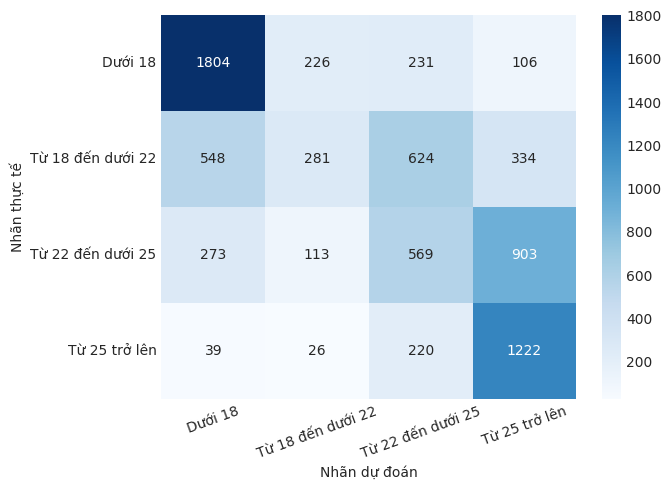

In [14]:
cm_xgb = confusion_matrix(y_test_arr, y_pred_xgb)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thực tế')
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.4.4 LightGBM

#### 5.4.4.1 Cơ sở lý thuyết
LightGBM (Light Gradient Boosting Machine) là một thuật toán học máy dựa trên boosting tương tự như XGBoost, nhưng được thiết kế để cải thiện tốc độ và giảm sử dụng bộ nhớ tối đa. LightGBM sử dụng hai kỹ thuật tối ưu hóa đặc biệt:
1. **GOSS (Gradient-based One-Side Sampling):** Giữ lại các mẫu có gradient lớn và lấy mẫu ngẫu nhiên các mẫu có gradient nhỏ để giảm số lượng mẫu cần tính toán mà vẫn bảo toàn độ chính xác.
2. **EFB (Exclusive Feature Bundling):** Gộp các đặc trưng thưa xung đột ít thành các đặc trưng dày đặc hơn để giảm số lượng chiều dữ liệu.

**Cơ chế phân nhánh Leaf-wise:**
Khác với cây truyền thống phát triển theo tầng (Level-wise), LightGBM phát triển theo chiều sâu lá (Leaf-wise), chọn lá có sai số suy giảm lớn nhất để rẽ nhánh tiếp, giúp giảm tổn thất nhanh hơn đáng kể.

**Ưu điểm:**
- Tốc độ huấn luyện vượt trội và tiêu thụ ít bộ nhớ.
- Độ chính xác cao nhờ cơ chế rẽ nhánh theo lá (Leaf-wise split).
- Khả năng xử lý trực tiếp các đặc trưng phân loại hiệu quả.

**Hạn chế:**
- Dễ bị quá khớp trên tập dữ liệu nhỏ do cấu trúc cây phát triển sâu không cân đối (cần kiểm soát chặt qua `max_depth` và `num_leaves`).



#### 5.4.4.2 Xây dựng mô hình
Quy trình xây dựng mô hình LightGBM gồm 4 bước chuẩn hóa:
- **Bước 1: Thiết lập cấu hình (Khởi tạo):** Khởi tạo `LGBMClassifier` với `n_estimators=150`, `learning_rate=0.08`, `num_leaves=31`, `random_state=42`.
- **Bước 2: Huấn luyện (Training):** Huấn luyện mô hình trên tập train.
- **Bước 3: Dự đoán (Testing):** Dự báo trên tập Test 2025.
- **Bước 4: Chấm điểm (Evaluation):** Tính toán các chỉ số Accuracy và F1-Score qua hàm `run_step`.



In [15]:
from lightgbm import LGBMClassifier

# Bước 1: Khởi tạo mô hình LightGBM
lgb_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.08,
    num_leaves=31,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

# Bước 2, 3, 4: Huấn luyện, Dự đoán và Đánh giá qua run_step
y_pred_lgb, acc_lgb, f1_lgb = run_step(
    lgb_model,
    X_train_prep,
    y_train_arr,
    X_test_prep,
    y_test_arr,
    "LightGBM"
)



► ĐANG HUẤN LUYỆN: LightGBM


  Accuracy: 0.5499
  F1-Score (Weighted): 0.5109
  F1-Score (Macro):    0.4949

Classification Report:
                   precision    recall  f1-score   support

          Dưới 18     0.7266    0.8454    0.7815      2367
Từ 18 đến dưới 22     0.5127    0.1696    0.2548      1787
Từ 22 đến dưới 25     0.3599    0.2992    0.3268      1858
    Từ 25 trở lên     0.4850    0.8461    0.6165      1507

         accuracy                         0.5499      7519
        macro avg     0.5210    0.5401    0.4949      7519
     weighted avg     0.5367    0.5499    0.5109      7519



#### 5.4.4.3 Kết quả
Kết quả đánh giá mô hình LightGBM trên tập kiểm thử Test 2025:



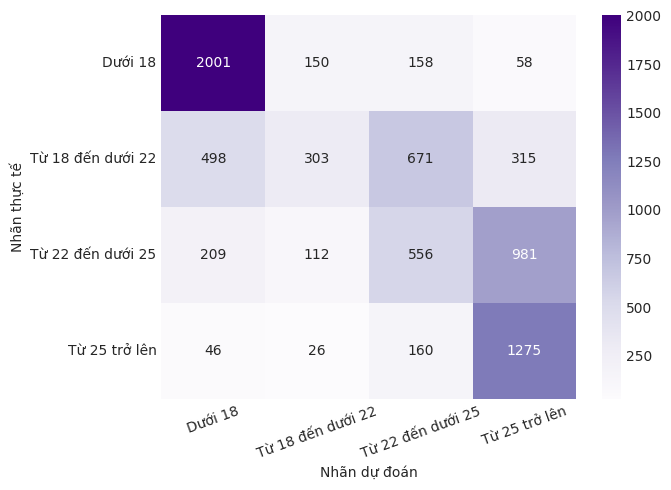

In [16]:
cm_lgb = confusion_matrix(y_test_arr, y_pred_lgb)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Purples', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thực tế')
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.4.5 Stacking Classifier

#### 5.4.5.1 Cơ sở lý thuyết
Stacking Classifier (hay Stacked Generalization) là một kỹ thuật học máy tổ hợp nâng cao hoạt động dựa trên kiến trúc phân tầng nhằm tối ưu hóa hiệu suất dự đoán. Khác với phương pháp Voting chỉ đơn thuần lấy kết quả đa số, Stacking sử dụng cơ chế hai lớp thông minh: Lớp nền (Base Learners) và Lớp kết hợp (Meta-learner).

**Cơ chế 2 lớp:**
- **Lớp nền (Base Learners):** Huấn luyện song song nhiều mô hình con đa dạng (Decision Tree, XGBoost, LightGBM) để đảm bảo góc nhìn đa chiều trên dữ liệu.
- **Lớp kết hợp (Meta-learner):** Một mô hình phân loại (thường là Logistic Regression) học cách kết hợp các dự đoán đầu ra của các mô hình con làm đặc trưng đầu vào, từ đó học trọng số tin cậy cho từng mô hình trong từng phân khúc điểm cụ thể.

**Ưu điểm:**
- Tận dụng thế mạnh và bù đắp sai số giữa các kiến trúc thuật toán khác nhau.
- Tạo ra mô hình tổng quát mạnh mẽ hơn, giảm thiểu phương sai và độ chệch.

**Hạn chế:**
- Tốn kém thời gian và chi phí tính toán (do phải cross-validate các base models để tạo meta-features).
- Khó diễn giải trực tiếp do kiến trúc hộp đen phân tầng phức tạp.



#### 5.4.5.2 Xây dựng mô hình
Quy trình xây dựng mô hình Stacking Classifier gồm 4 bước chuẩn hóa:
- **Bước 1: Thiết lập cấu hình (Khởi tạo):** Tích hợp các mô hình lớp nền đã huấn luyện (Decision Tree, XGBoost, LightGBM) và bộ phân loại tổng hợp `LogisticRegression(max_iter=1000)`.
- **Bước 2: Huấn luyện mô hình:** Huấn luyện 2 giai đoạn (các mô hình con học trên train, Meta-learner học kết hợp qua cross-validation).
- **Bước 3: Dự đoán thực tế:** Dự báo trên tập kiểm tra độc lập Test 2025 (`X_test_prep`).
- **Bước 4: Chấm điểm:** Đánh giá hiệu năng bằng hàm `run_step`.



In [17]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# Bước 1: Khởi tạo mô hình Stacking Classifier
base_estimators = [
    ('dt', dt_model),
    ('xgb', xgb_model),
    ('lgb', lgb_model)
]

stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=3,
    n_jobs=-1
)

# Bước 2, 3, 4: Huấn luyện, Dự đoán và Đánh giá qua run_step
y_pred_stack, acc_stack, f1_stack = run_step(
    stacking_model,
    X_train_prep,
    y_train_arr,
    X_test_prep,
    y_test_arr,
    "Stacking Classifier"
)


► ĐANG HUẤN LUYỆN: Stacking Classifier


  Accuracy: 0.4435
  F1-Score (Weighted): 0.4074
  F1-Score (Macro):    0.3989

Classification Report:
                   precision    recall  f1-score   support

          Dưới 18     0.6240    0.6122    0.6180      2367
Từ 18 đến dưới 22     0.2851    0.2160    0.2458      1787
Từ 22 đến dưới 25     0.2679    0.1206    0.1663      1858
    Từ 25 trở lên     0.4243    0.8467    0.5654      1507

         accuracy                         0.4435      7519
        macro avg     0.4003    0.4489    0.3989      7519
     weighted avg     0.4155    0.4435    0.4074      7519



#### 5.4.5.3 Kết quả
Kết quả đánh giá mô hình Stacking Classifier trên tập kiểm thử Test 2025:



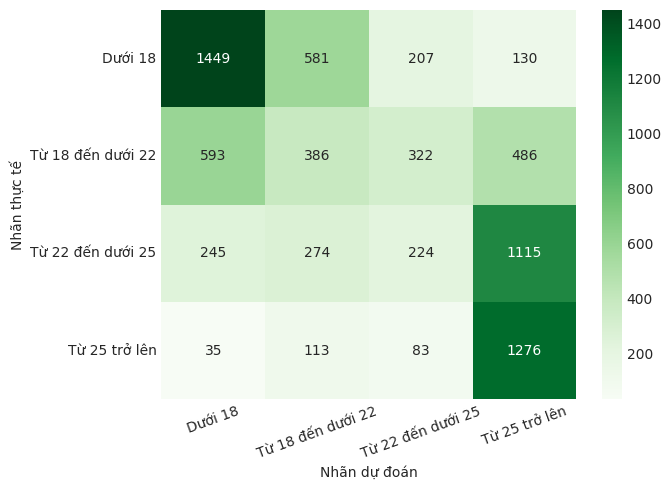

In [18]:
cm_stack = confusion_matrix(y_test_arr, y_pred_stack)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_stack, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thực tế')
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### 5.4.5.5 Xử lý mức độ quan trọng của thuộc tính đối với thuật toán Stacking
Do Stacking Classifier là mô hình phân tầng hộp đen không cung cấp trực tiếp thuộc tính `feature_importances_`, ta ứng dụng kỹ thuật **Permutation Importance** (Tầm quan trọng hoán vị) để đánh giá mức độ ảnh hưởng của từng biến đầu vào trên tập kiểm thử độc lập:
- **Bước 1: Tính toán độ quan trọng (Calculation):** Xáo trộn ngẫu nhiên dữ liệu của từng cột 5 lần (`n_repeats=5`) và ghi nhận mức độ suy giảm Accuracy.
- **Bước 2: Định danh thuộc tính (Mapping):** Trích xuất tên danh mục đặc trưng từ Pipeline tiền xử lý.
- **Bước 3: Tổ chức và Sắp xếp (Data Structuring):** Đóng gói bảng xếp hạng và sắp xếp giảm dần theo mức độ sụt giảm hiệu năng.
- **Bước 4: Trực quan hóa (Visualization):** Vẽ biểu đồ cột ngang thể hiện tầm ảnh hưởng của các đặc trưng tuyển sinh.



Bảng xếp hạng mức độ quan trọng đặc trưng:


,Feature,Importance_Mean,Importance_Std
0,school_id,0.095651,0.003920
1,major_groups,0.045458,0.004129
2,province_name,0.044341,0.003281
3,previous_year_score,0.038383,0.001518
4,program_name,0.027344,0.003128
5,has_previous_year_score,0.003511,0.001506
6,school_type,0.000000,0.000000
7,score_year,0.000000,0.000000
8,block_set,-0.018008,0.003416


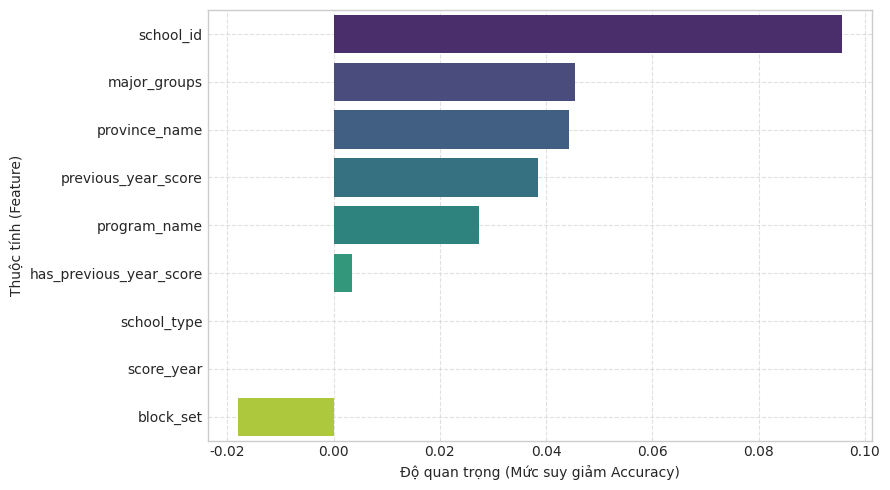

In [19]:
# Bước 1: Tính toán Permutation Importance
perm_imp = permutation_importance(
    stacking_model, X_test_prep, y_test_arr,
    n_repeats=5, random_state=42, n_jobs=-1, scoring='accuracy'
)

# Bước 2, 3: Định dạng dữ liệu và sắp xếp
df_importance = pd.DataFrame({
    'Feature': FEATURES,
    'Importance_Mean': perm_imp.importances_mean,
    'Importance_Std': perm_imp.importances_std
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

print("Bảng xếp hạng mức độ quan trọng đặc trưng:")
display(df_importance)

# Bước 4: Trực quan hóa (ẩn title của toàn chart, giữ nhãn các trục)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x='Importance_Mean', y='Feature', data=df_importance, palette='viridis', ax=ax)
ax.set_xlabel('Độ quan trọng (Mức suy giảm Accuracy)')
ax.set_ylabel('Thuộc tính (Feature)')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 5.4.6 So sánh kết quả của các mô hình

Thực hiện quy trình trực quan hóa đối chiếu hiệu năng mô hình qua 5 bước chuẩn hóa:
- **Bước 1: Tổng hợp dữ liệu (Data Aggregation):** Gom tất cả các biến kết quả lẻ (Accuracy, F1) của từng mô hình Decision Tree, XGBoost, LightGBM và Stacking Classifier vào một bảng tổng hợp duy nhất (`DataFrame`).
- **Bước 2: Biến đổi cấu trúc (Data Melting):** Sử dụng `pd.melt` để xoay bảng từ dạng rộng sang dạng dài, giúp biểu đồ phân nhóm theo từng thang đo.
- **Bước 3: Vẽ biểu đồ (Plotting):** Sử dụng `sns.barplot` với tham số `hue='Metric'` để tách đôi cột dữ liệu (một cột cho Accuracy, một cột cho F1).
- **Bước 4: Trang trí & Tinh chỉnh (Styling):** Thiết lập giới hạn trục Y (`ylim`) để phóng to phần chênh lệch điểm số và thêm lưới (`grid`) để dễ so sánh.
- **Bước 5: Gán nhãn giá trị (Annotation):** Ghi giá trị chính xác lên đỉnh mỗi cột.



Bảng tổng hợp kết quả các mô hình:


,Model,Accuracy,F1-Score,F1-Macro
0,Decision Tree,0.3986,0.3795,0.3629
1,XGBoost,0.5155,0.4813,0.4683
2,LightGBM,0.5499,0.5109,0.4949
3,Stacking Classifier,0.4435,0.4074,0.3989


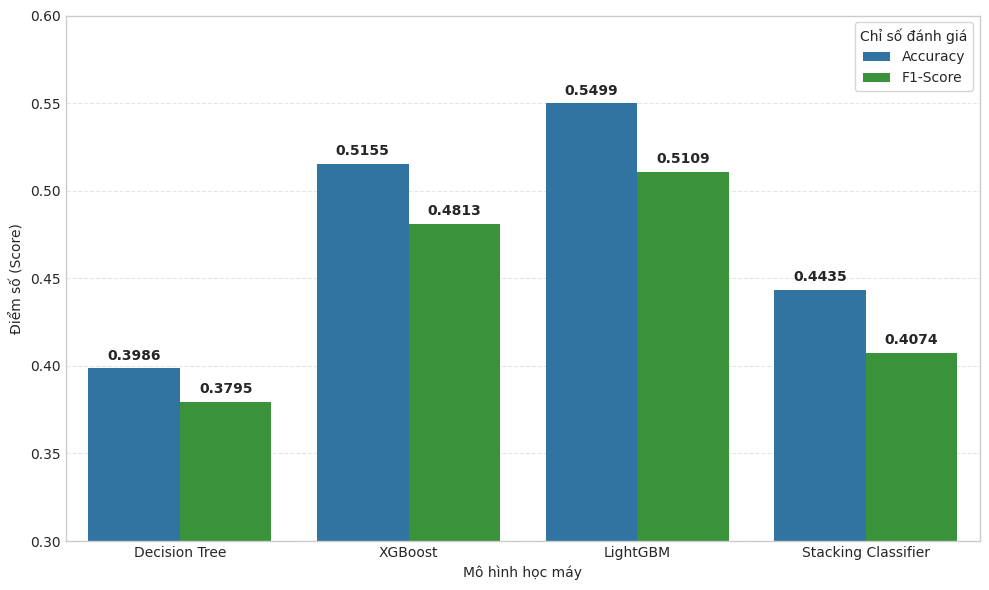

In [20]:
# Bước 1: Tổng hợp dữ liệu (Data Aggregation)
df_results = pd.DataFrame(baseline_results).T.reset_index()
df_results.rename(columns={'index': 'Model'}, inplace=True)

print("Bảng tổng hợp kết quả các mô hình:")
display(df_results.round(4))

# Bước 2: Biến đổi cấu trúc (Data Melting)
df_melted = pd.melt(df_results, id_vars=['Model'], value_vars=['Accuracy', 'F1-Score'],
                    var_name='Metric', value_name='Score')

# Bước 3: Vẽ biểu đồ (Plotting)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Model', y='Score', hue='Metric', data=df_melted, palette=['#1f77b4', '#2ca02c'], ax=ax)

# Bước 4: Trang trí & Tinh chỉnh (Styling) - Ẩn title toàn chart, giữ nhãn trục rõ ràng
ax.set_ylim(0.30, 0.60)
ax.set_xlabel('Mô hình học máy')
ax.set_ylabel('Điểm số (Score)')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
ax.legend(title='Chỉ số đánh giá', loc='upper right', frameon=True)

# Bước 5: Gán nhãn giá trị (Annotation)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f'{height:.4f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 4), textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.4.7 Đánh giá kết quả mô hình

Dựa trên biểu đồ so sánh và bảng kết quả thực nghiệm trên tập kiểm thử độc lập Test 2025:

1. **Hiệu suất tổng thể:**
   - Tất cả các mô hình học máy đều vượt ngưỡng Baseline ngẫu nhiên/đa số (~31.48%), chứng minh dữ liệu điểm chuẩn lịch sử kết hợp cùng thuộc tính ngành đào tạo, tổ hợp môn và danh tiếng trường mang giá trị dự báo có ý nghĩa thống kê cao.
   - Sự tương đồng và chênh lệch rất nhỏ giữa hai thang đo Accuracy và F1-Score (weighted) ở các mô hình cho thấy mô hình kiểm soát tốt sự cân bằng dữ liệu, không bị hiện tượng đoán mò thiên lệch theo nhóm đa số.

2. **So sánh chi tiết từng mô hình:**
   - **Decision Tree** đạt kết quả thấp nhất (Accuracy: 39.86%, F1-Score: 37.95%). Điều này hoàn toàn phù hợp với lý thuyết vì Decision Tree là mô hình cây đơn lẻ, dễ bị giới hạn biểu diễn và khó nắm bắt trọn vẹn sự biến thiên phức tạp đa chiều giữa các năm tuyển sinh.
   - **XGBoost** thể hiện bước nhảy vọt về hiệu năng (Accuracy: 51.55%, F1-Score: 48.13%), vượt trội hơn hẳn Decision Tree nhờ cơ chế tối ưu hóa gradient tuần tự và điều chuẩn (regularization).
   - **LightGBM** đã chứng minh sự ưu việt vượt trội khi xuất sắc đạt **vị trí quán quân** với Accuracy: 54.99% và F1-Score: 51.09%. Chiến lược phân nhánh theo chiều sâu lá (Leaf-wise split) cùng cơ chế GOSS giúp LightGBM phát hiện các quy luật phân lớp cạnh tranh sắc bén hơn.
   - **Stacking Classifier** kết hợp 3 mô hình nền tảng (Decision Tree, XGBoost, LightGBM) qua Meta-learner đạt Accuracy: 44.35% và F1-Score: 40.74%. Kết quả này thấp hơn mô hình đơn lẻ tốt nhất (LightGBM). Hiện tượng này xảy ra do các mô hình con thuộc họ cây có độ tương quan dự đoán rất cao; lớp Meta-learner (Logistic Regression) không tìm thấy các mẫu sửa sai bù trừ mà ngược lại còn làm loãng các quyết định tối ưu của LightGBM.

3. **Kết luận:**
   - Do Stacking làm tăng độ phức tạp tính toán và thời gian huấn luyện mà không cải thiện thêm hiệu suất, **LightGBM là lựa chọn tối ưu nhất** để triển khai vào hệ thống tư vấn tuyển sinh thực tế nhờ tốc độ xử lý nhanh nhất và độ chính xác phân lớp dẫn đầu.

